<a href="https://colab.research.google.com/github/Revaant-D/5_Unopsis/blob/feature%2Fai-assignment-7/a7/multi_model_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unopsis — multi-model system (Assignment 7)

**Team 5 · INFO 490 MG · Fall 2026**

Unopsis reads a user's messages (e-mail, Slack, WhatsApp, Discord) and turns them into one
short daily brief. This notebook takes the **15 models from Assignment 6** and benchmarks them
on **25 Unopsis prompts across 5 prompt types**, then uses the measured speed to simulate
cost at six traffic scales and to test five routing strategies.

| Part | Sections | What happens |
|---|---|---|
| 1 Benchmarking | 1.1 – 1.6 | categories, prompt types, 25 prompts, metrics, 15 × 25 = 375 runs, analysis |
| 2 Cost & infrastructure | 2.1 – 2.5 | token load, local hosting (90 rows), Hugging Face API (90 rows), comparison |
| 3 Routing | 3.1 – 3.3 | five scenarios, a router, and a simulation of latency / cost / quality |

**Run it in Google Colab with a GPU:** *Runtime → Change runtime type → T4 GPU*, then
*Runtime → Run all*. Models up to 4B load in fp16; the 7B–15B models load in 4-bit so they fit
in the T4's 16 GB. Expect roughly 1–2 hours, mostly downloads. Results are saved to `results/`
after every model, so if Colab disconnects, run all again and it continues where it stopped.
The written reasoning (architecture, costs, routing) is in `system_design.md`.

In [1]:
# ==== TOP CELL: install libraries + download model weights ================================
%pip install -q "transformers>=4.51" "accelerate>=0.30" huggingface_hub pandas matplotlib psutil

import torch
if torch.cuda.is_available():
    %pip install -q bitsandbytes          # 4-bit loading for the 7B-15B models (GPU only)

import gc, json, math, os, re, shutil, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from huggingface_hub import snapshot_download
from transformers import AutoModelForCausalLM, AutoTokenizer

HF_TOKEN = os.environ.get("HF_TOKEN") or None   # optional: none of the 15 models is gated
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "-"
GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE == "cuda" else 0.0
try:
    import psutil
    RAM_GB = psutil.virtual_memory().total / 1e9
except ImportError:
    RAM_GB = 16.0
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
print(f"torch {torch.__version__} | device={DEVICE} ({GPU_NAME}, {GPU_MEM_GB:.0f} GB) | RAM {RAM_GB:.0f} GB")

IGNORE = ["*.bin", "*.pth", "*.pt", "*.gguf", "*.onnx", "*.h5", "*.msgpack", "*.tflite",
          "original/*", "onnx/*", "coreml/*"]

def download(model_id, params_b):
    need = params_b * 2 + 3
    free = shutil.disk_usage(Path.home()).free / 1e9
    if free < need:
        raise RuntimeError(f"not enough disk for {model_id}: ~{need:.0f} GB needed, {free:.0f} GB free")
    return snapshot_download(model_id, ignore_patterns=IGNORE, token=HF_TOKEN)

# Pre-download the 9 models under 5B now (~23 GB). The 7B-15B models are downloaded right
# before they are tested and deleted right after, so the Colab disk never holds them all.
PREDOWNLOAD = True

torch 2.11.0+cu130 | device=cuda (Tesla T4, 16 GB) | RAM 14 GB


## Step 1.1 — Model size categories

The same 15 models as Assignment 6: three per category, each from a **different model family**,
so a category compares different training approaches rather than three sizes of one model.
Our ranges follow the sizes that actually exist among small open chat models and that fit on a
free GPU; we have no 30B+ category because a 30B model needs more than the T4's 16 GB even in
4-bit.

| Category | Parameter range | Models |
|---|---|---|
| Ultra-Light | < 1B | SmolLM2-360M-Instruct · Qwen2.5-0.5B-Instruct · Qwen3-0.6B |
| Small | 1B – 2B | Qwen2.5-1.5B-Instruct · SmolLM2-1.7B-Instruct · Qwen3-1.7B |
| Medium | 2B – 4B | Granite-3.3-2B-Instruct · Qwen2.5-3B-Instruct · Phi-4-mini-instruct (3.8B) |
| Large | 7B – 9B | OLMo-2-7B-Instruct · Qwen2.5-7B-Instruct · Granite-3.3-8B-Instruct |
| Very Large | 12B – 15B | OLMo-2-13B-Instruct · Qwen2.5-14B-Instruct · Phi-4 (14.7B) |

In [2]:
CATALOG = [
    dict(category="1 Ultra-Light (<1B)", model_id="HuggingFaceTB/SmolLM2-360M-Instruct", params_b=0.36),
    dict(category="1 Ultra-Light (<1B)", model_id="Qwen/Qwen2.5-0.5B-Instruct",          params_b=0.49),
    dict(category="1 Ultra-Light (<1B)", model_id="Qwen/Qwen3-0.6B",                     params_b=0.60),
    dict(category="2 Small (1-2B)",      model_id="Qwen/Qwen2.5-1.5B-Instruct",          params_b=1.54),
    dict(category="2 Small (1-2B)",      model_id="HuggingFaceTB/SmolLM2-1.7B-Instruct", params_b=1.71),
    dict(category="2 Small (1-2B)",      model_id="Qwen/Qwen3-1.7B",                     params_b=1.72),
    dict(category="3 Medium (2-4B)",     model_id="ibm-granite/granite-3.3-2b-instruct", params_b=2.53),
    dict(category="3 Medium (2-4B)",     model_id="Qwen/Qwen2.5-3B-Instruct",            params_b=3.09),
    dict(category="3 Medium (2-4B)",     model_id="microsoft/Phi-4-mini-instruct",       params_b=3.84),
    dict(category="4 Large (7-9B)",      model_id="allenai/OLMo-2-1124-7B-Instruct",     params_b=7.30),
    dict(category="4 Large (7-9B)",      model_id="Qwen/Qwen2.5-7B-Instruct",            params_b=7.62),
    dict(category="4 Large (7-9B)",      model_id="ibm-granite/granite-3.3-8b-instruct", params_b=8.17),
    dict(category="5 Very Large (12-15B)", model_id="allenai/OLMo-2-1124-13B-Instruct",  params_b=13.72),
    dict(category="5 Very Large (12-15B)", model_id="Qwen/Qwen2.5-14B-Instruct",         params_b=14.77),
    dict(category="5 Very Large (12-15B)", model_id="microsoft/phi-4",                   params_b=14.66),
]
print(pd.DataFrame(CATALOG).to_string(index=False))

if PREDOWNLOAD:
    for e in CATALOG:
        if e["params_b"] < 5:
            try:
                download(e["model_id"], e["params_b"]); print("  downloaded", e["model_id"])
            except Exception as exc:
                print("  ", e["model_id"], "->", exc)

             category                            model_id  params_b
  1 Ultra-Light (<1B) HuggingFaceTB/SmolLM2-360M-Instruct      0.36
  1 Ultra-Light (<1B)          Qwen/Qwen2.5-0.5B-Instruct      0.49
  1 Ultra-Light (<1B)                     Qwen/Qwen3-0.6B      0.60
       2 Small (1-2B)          Qwen/Qwen2.5-1.5B-Instruct      1.54
       2 Small (1-2B) HuggingFaceTB/SmolLM2-1.7B-Instruct      1.71
       2 Small (1-2B)                     Qwen/Qwen3-1.7B      1.72
      3 Medium (2-4B) ibm-granite/granite-3.3-2b-instruct      2.53
      3 Medium (2-4B)            Qwen/Qwen2.5-3B-Instruct      3.09
      3 Medium (2-4B)       microsoft/Phi-4-mini-instruct      3.84
       4 Large (7-9B)     allenai/OLMo-2-1124-7B-Instruct      7.30
       4 Large (7-9B)            Qwen/Qwen2.5-7B-Instruct      7.62
       4 Large (7-9B) ibm-granite/granite-3.3-8b-instruct      8.17
5 Very Large (12-15B)    allenai/OLMo-2-1124-13B-Instruct     13.72
5 Very Large (12-15B)           Qwen/Qwen2.5-14B

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

  downloaded HuggingFaceTB/SmolLM2-360M-Instruct


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

  downloaded Qwen/Qwen2.5-3B-Instruct


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

  downloaded microsoft/Phi-4-mini-instruct


## Step 1.2 — Prompt types

Five prompt types, each one a real job inside Unopsis:

| Prompt type | Unopsis job | Expected output |
|---|---|---|
| **Classification** | Put an incoming message in a lane | JSON `{"lane": "needs_you" \| "moving" \| "fyi" \| "noise"}` |
| **Summarization** | Turn a message or thread into one line of the brief | plain text, ≤ 15 words |
| **Structured extraction** | Pull out who, what and by when | JSON `{"sender", "action", "deadline"}` |
| **Text generation** | Draft a reply the user can edit (never sent automatically) | plain text, 1–3 sentences, ≤ 60 words |
| **Prediction** | Predict urgency to rank the brief | JSON `{"urgency": 1–5, "reply_needed_today": true/false}` |

In [3]:
SYSTEM = {
    "classification": (
        "You triage messages for a busy student. Classify the message into exactly one lane and "
        'answer with JSON only: {"lane": "needs_you" | "moving" | "fyi" | "noise"}. '
        "needs_you = the reader must reply, decide or act. moving = someone else is handling it. "
        "fyi = useful to know, no action. noise = ads, promotions, automated mail."),
    "summarization": (
        "Summarize the message for a daily brief in ONE sentence of at most 15 words. "
        "Keep names, dates and deadlines. Reply with the sentence only, no JSON, no preamble."),
    "extraction": (
        "Extract the key facts from the message and answer with JSON only: "
        '{"sender": "<who sent it>", "action": "<what the reader must do, or null>", '
        '"deadline": "<the deadline as written, or null>"}'),
    "generation": (
        "Draft a short, polite reply the user could send, in 1 to 3 sentences and at most 60 "
        "words. Follow the user's intent exactly. Do not invent facts. Reply with the message text only."),
    "prediction": (
        "Predict how urgent the message is for the reader and answer with JSON only: "
        '{"urgency": <integer 1-5, 5 = most urgent>, "reply_needed_today": true | false}'),
}
MAX_NEW_TOKENS = {"classification": 30, "summarization": 40, "extraction": 70,
                  "generation": 110, "prediction": 30}

## Step 1.3 — The 25 evaluation prompts

Five per type, written to look like what Unopsis actually receives (several come straight from
the app's demo data). Each prompt also carries what a correct answer must contain, which the
scoring in Step 1.4 checks.

In [4]:
PROMPTS = [
    # ---------- classification: expected lane ----------
    dict(id="C1", type="classification", expect={"lane": "needs_you"}, text="Your draft looks solid. Tighten section 3 and resend before Friday."),
    dict(id="C2", type="classification", expect={"lane": "moving"},    text="confirmed: migration 0004 locks the table. rolling back."),
    dict(id="C3", type="classification", expect={"lane": "noise"},     text="FLASH SALE: 50% off all textbook rentals!"),
    dict(id="C4", type="classification", expect={"lane": "fyi"},       text="fyi the career fair moved to the Union ballroom, same time"),
    dict(id="C5", type="classification", expect={"lane": "needs_you"}, text="Invoice #4471 is 14 days overdue. Please approve payment."),
    # ---------- summarization: keywords the summary must keep (| = any of) ----------
    dict(id="S1", type="summarization", expect={"keywords": ["rubric|er diagram", "friday"]},
         text="Priya: did everyone see the rubric got updated? Devon: wait it changed again?? Priya: yes, ER diagram is required now. Sam: ok who's doing it? Priya: due friday, hard deadline per the syllabus"),
    dict(id="S2", type="summarization", expect={"keywords": ["thursday", "slides", "wednesday"]},
         text="Hi team, the client moved our demo from Tuesday to Thursday at 2pm because their VP is traveling. Please update the slides with the new pricing tier and send them to me by Wednesday noon so I can review. Thanks, Maya"),
    dict(id="S3", type="summarization", expect={"keywords": ["staging|deploy", "migration", "roll"]},
         text="Devon: deploy to staging failed again, third time today. Sam: looking into it, probably the migration. Sam: confirmed: migration 0004 locks the table. rolling back."),
    dict(id="S4", type="summarization", expect={"keywords": ["dinner|birthday", "sunday"]},
         text="Mom: call me when you get a chance sweetie. also grandma's birthday dinner is sunday at 6, can you make it? bring the cake from that bakery you like"),
    dict(id="S5", type="summarization", expect={"keywords": ["study room|library", "nov"]},
         text="Reminder: the library's 24-hour study rooms close for renovation from Nov 3 to Nov 14. Bookings during that window are cancelled automatically; you can rebook at Grainger."),
    # ---------- structured extraction: sender / action / deadline ----------
    dict(id="E1", type="extraction", expect={"sender": "ramirez", "action": "proposal", "deadline": "friday"},
         text="From: Prof. Ramirez -- Please submit the revised proposal by Friday 5pm."),
    dict(id="E2", type="extraction", expect={"sender": "lena", "action": "book", "deadline": "15"},
         text="Lena: found flights for $180 round trip, we need to book by the 15th or the price goes up"),
    dict(id="E3", type="extraction", expect={"sender": "northwind", "action": "approv", "deadline": None},
         text="Northwind Billing: Second notice: Invoice #4471 requires your approval to avoid a late fee."),
    dict(id="E4", type="extraction", expect={"sender": "sam", "action": "review", "deadline": "tomorrow"},
         text="Sam (Slack #engineering): can someone review PR #212 before standup tomorrow at 9?"),
    dict(id="E5", type="extraction", expect={"sender": "chen", "action": "confirm", "deadline": "oct 30|30"},
         text="Dr. Chen's office: your appointment is confirmed for Oct 30 at 10:15am, reply C to confirm or R to reschedule"),
    # ---------- text generation: the user's intent + words the reply should contain ----------
    dict(id="G1", type="generation", expect={"keywords": ["section 3|revis", "friday"]},
         text="Message from Prof. Ramirez: 'Your draft looks solid. Tighten section 3 and resend before Friday.' Intent: thank them and say I will send the revised draft before Friday."),
    dict(id="G2", type="generation", expect={"keywords": ["sunday|dinner"]},
         text="Message from Mom: 'grandma's birthday dinner is sunday at 6, can you make it?' Intent: say yes, I'll be there and I'll bring the cake."),
    dict(id="G3", type="generation", expect={"keywords": ["march", "april"]},
         text="Message from Lena: 'are we still doing the trip in march?' Intent: politely say March doesn't work for me and suggest April instead."),
    dict(id="G4", type="generation", expect={"keywords": ["4471|invoice", "today"]},
         text="Message from Northwind Billing: 'Invoice #4471 is 14 days overdue. Please approve payment.' Intent: apologise for the delay and say I will approve it today."),
    dict(id="G5", type="generation", expect={"keywords": ["models", "when|deadline|by"]},
         text="Message from Devon in the team Slack: 'someone needs to own the models file'. Intent: volunteer to take it and ask when it is needed."),
    # ---------- prediction: acceptable urgency range + reply today? ----------
    dict(id="P1", type="prediction", expect={"urgency": (4, 5), "reply_today": True},
         text="Server is down for all customers, we need someone on the incident call NOW."),
    dict(id="P2", type="prediction", expect={"urgency": (1, 1), "reply_today": False},
         text="You left something in your cart"),
    dict(id="P3", type="prediction", expect={"urgency": (3, 5), "reply_today": True},
         text="can you confirm by tonight whether you're coming to dinner? need to tell the restaurant"),
    dict(id="P4", type="prediction", expect={"urgency": (1, 2), "reply_today": False},
         text="Here are the meeting notes from last week for reference, no action needed."),
    dict(id="P5", type="prediction", expect={"urgency": (3, 5), "reply_today": True},
         text="Invoice #4471 is 14 days overdue. Please approve payment today to avoid a late fee."),
]
print(pd.Series([p["type"] for p in PROMPTS]).value_counts().to_string(), "\ntotal:", len(PROMPTS))

classification    5
summarization     5
extraction        5
generation        5
prediction        5 
total: 25


## Step 1.4 — Evaluation metrics

Every output gets four scores from 1 to 10. The **self-evaluation score** is their average.

| Metric | Question | How it is scored |
|---|---|---|
| **Instruction adherence** | Did the model do exactly what was asked? | Only the requested output, no preamble or extra text; length limit respected (≤ 15 words for a summary, ≤ 60 for a reply) |
| **Accuracy** | Was the answer correct? | Classification: right lane. Extraction: right sender / action / deadline. Prediction: urgency in the acceptable range and right reply-today flag. Summary / reply: keeps the facts listed for that prompt |
| **Clarity** | Is it understandable? | Complete (not cut off mid-sentence), no repeated phrases, no leftover template tokens or placeholders |
| **Structure** | Is it in the expected format? | JSON types: valid JSON with exactly the required keys and allowed values. Text types: plain text, no JSON or markdown |

**How we scored all 375 outputs.** We wrote the rubric above as code (`score_output` below) so
every model is judged identically. We then read a sample by hand (one output per prompt type
per model) and corrected any score we disagreed with in `MANUAL_OVERRIDES` (Step 1.5b). Those
corrections are kept in the notebook, so the scoring is reproducible.

In [5]:
def find_json(text):
    # First balanced {...} in the text, parsed; None if there is none.
    text = re.sub(r"```(?:json)?", "", text or "")
    start = text.find("{")
    while start != -1:
        depth, in_str, esc = 0, False, False
        for i in range(start, len(text)):
            ch = text[i]
            if in_str:
                if esc:
                    esc = False
                elif ch == "\\":
                    esc = True
                elif ch == '"':
                    in_str = False
                continue
            if ch == '"':
                in_str = True
            elif ch == "{":
                depth += 1
            elif ch == "}":
                depth -= 1
                if depth == 0:
                    try:
                        val = json.loads(text[start:i + 1])
                        return val if isinstance(val, dict) else None
                    except ValueError:
                        break
        start = text.find("{", start + 1)
    return None


def has(text, pattern):
    # pattern like "rubric|er diagram": any alternative present (case-insensitive)
    t = (text or "").lower()
    return any(alt in t for alt in pattern.lower().split("|"))


def clamp(x):
    return max(1, min(10, int(round(x))))


JSON_KEYS = {"classification": {"lane"}, "extraction": {"sender", "action", "deadline"},
             "prediction": {"urgency", "reply_needed_today"}}
LANES = {"needs_you", "moving", "fyi", "noise"}


def score_output(prompt, raw):
    kind, exp = prompt["type"], prompt["expect"]
    raw = (raw or "").strip()
    words = len(raw.split())
    s = {}

    # ---- clarity: complete, not repetitive, no junk ----
    tokens = re.findall(r"\w+", raw.lower())
    unique = len(set(tokens)) / len(tokens) if tokens else 0
    clarity = 10
    if not raw:
        clarity = 1
    else:
        if raw[-1] not in '.!?"}\')': clarity -= 3                # cut off mid-sentence
        if len(tokens) > 12 and unique < 0.5: clarity -= 4       # repeats itself
        if re.search(r"<\|.*?\|>|\[INST\]|\[your name\]|\[name\]", raw, re.I): clarity -= 3
    s["clarity"] = clamp(clarity)

    if kind in JSON_KEYS:
        obj = find_json(raw)
        keys = JSON_KEYS[kind]
        # ---- structure ----
        if obj is None:
            s["structure"] = 1
        elif set(obj) == keys:
            s["structure"] = 10
        elif keys <= set(obj):
            s["structure"] = 7
        else:
            s["structure"] = 4
        # ---- adherence: JSON only, nothing around it ----
        only_json = raw.startswith("{") and raw.endswith("}")
        fenced = raw.startswith("```")
        s["adherence"] = 10 if only_json else (7 if fenced else (4 if obj else 1))
        # ---- accuracy ----
        acc = 1
        if obj:
            if kind == "classification":
                lane = str(obj.get("lane", "")).strip().lower().replace(" ", "_")
                acc = 10 if lane == exp["lane"] else (3 if lane in LANES else 1)
            elif kind == "extraction":
                pts = 0
                pts += has(str(obj.get("sender", "")), exp["sender"])
                pts += has(str(obj.get("action", "")), exp["action"])
                dl = obj.get("deadline")
                dl_empty = dl in (None, "", "null", "none", "None")
                pts += (dl_empty if exp["deadline"] is None else (not dl_empty and has(str(dl), exp["deadline"])))
                acc = 1 + 3 * pts                                   # 1, 4, 7, 10
            elif kind == "prediction":
                pts = 0
                try:
                    u = int(obj.get("urgency"))
                    lo, hi = exp["urgency"]
                    pts += 2 if lo <= u <= hi else (1 if lo - 1 <= u <= hi + 1 else 0)
                except (TypeError, ValueError):
                    pass
                r = obj.get("reply_needed_today")
                if isinstance(r, str):
                    r = r.strip().lower() == "true"
                pts += 1 if r == exp["reply_today"] else 0
                acc = {0: 1, 1: 4, 2: 7, 3: 10}[pts]
        s["accuracy"] = acc
    else:
        limit = 15 if kind == "summarization" else 60
        looks_json = raw.startswith("{")
        has_md = bool(re.search(r"^\s*[#*-] |\*\*", raw, re.M))
        preamble = bool(re.match(r"(sure|here('s| is)|summary:|reply:|draft:)", raw, re.I))
        # ---- structure: plain text ----
        s["structure"] = 1 if looks_json else (6 if has_md else 10)
        # ---- adherence: length + no preamble ----
        adh = 10
        if words > limit: adh -= min(6, 2 + (words - limit) // 5)
        if preamble: adh -= 3
        if kind == "generation" and len(re.findall(r"[.!?](\s|$)", raw)) > 3: adh -= 2
        s["adherence"] = clamp(adh)
        # ---- accuracy: keeps the required facts ----
        need = exp["keywords"]
        found = sum(has(raw, k) for k in need)
        s["accuracy"] = clamp(1 + 9 * found / len(need))

    s["score"] = round(sum(s[k] for k in ("adherence", "accuracy", "clarity", "structure")) / 4, 2)
    return s


# Quick self-check of the rubric on hand-written answers
print(score_output(PROMPTS[0], '{"lane": "needs_you"}'))
print(score_output(PROMPTS[0], 'Sure! The lane is needs_you.'))
print(score_output(PROMPTS[5], 'ER diagram now required by the updated rubric, due Friday.'))

{'clarity': 10, 'structure': 10, 'adherence': 10, 'accuracy': 10, 'score': 10.0}
{'clarity': 10, 'structure': 1, 'adherence': 1, 'accuracy': 1, 'score': 3.25}
{'clarity': 10, 'structure': 10, 'adherence': 10, 'accuracy': 10, 'score': 10.0}


## Step 1.5 — Run the benchmark (15 models × 25 prompts = 375 runs)

For each model: load it, run one untimed warm-up, then run all 25 prompts with greedy decoding
(`do_sample=False`, so results are reproducible). For every run we record:

* **Latency** — seconds from the start of `generate()` to the full answer
* **Tokens/sec** — generated tokens ÷ latency

Each model's rows are appended to `results/benchmark_raw.csv` as soon as it finishes, and a
model that already finished is skipped on a re-run.

In [6]:
def fits(e):
    p = e["params_b"]
    if DEVICE == "cuda":
        need = p * (0.65 if p > 5 else 2.1) + 1.0
        return need < GPU_MEM_GB, need
    need = p * (4.2 if p < 2 else 2.1) + 1.5
    return need < RAM_GB * 0.85, need


def load_model(e):
    p, kw = e["params_b"], {}
    if DEVICE == "cuda":
        if p > 5:
            from transformers import BitsAndBytesConfig
            kw["quantization_config"] = BitsAndBytesConfig(
                load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
            kw["device_map"] = "auto"
        else:
            kw["torch_dtype"] = torch.float16
            kw["device_map"] = "cuda"
    else:
        kw["torch_dtype"] = torch.float32 if p < 2 else torch.bfloat16
    tok = AutoTokenizer.from_pretrained(e["model_id"], token=HF_TOKEN)
    model = AutoModelForCausalLM.from_pretrained(e["model_id"], token=HF_TOKEN, **kw)
    model.eval()
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return tok, model


def build_chat(prompt):
    return [{"role": "system", "content": SYSTEM[prompt["type"]]},
            {"role": "user", "content": prompt["text"]}]


def to_inputs(tok, chat, device):
    kw = dict(add_generation_prompt=True, return_tensors="pt", return_dict=True, enable_thinking=False)
    try:
        enc = tok.apply_chat_template(chat, **kw)
    except Exception:   # template without a system role: merge it into the user turn
        enc = tok.apply_chat_template(
            [{"role": "user", "content": chat[0]["content"] + "\n\n" + chat[1]["content"]}], **kw)
    return enc.to(device)


def generate(tok, model, chat, max_new_tokens):
    enc = to_inputs(tok, chat, model.device)
    t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id)
    secs = time.perf_counter() - t0
    new = out[0][enc["input_ids"].shape[1]:]
    return tok.decode(new, skip_special_tokens=True).strip(), int(len(new)), int(enc["input_ids"].shape[1]), secs


def delete_from_cache(model_id):
    from huggingface_hub import scan_cache_dir
    info = scan_cache_dir()
    revs = [r.commit_hash for repo in info.repos if repo.repo_id == model_id for r in repo.revisions]
    if revs:
        info.delete_revisions(*revs).execute()


RAW = RESULTS / "benchmark_raw.csv"
META = RESULTS / "benchmark_meta.csv"


def append_csv(path, rows):
    if rows:
        pd.DataFrame(rows).to_csv(path, mode="a", header=not path.exists(), index=False)


done = set()
if META.exists():
    m = pd.read_csv(META)
    done = set(m.loc[m["status"] == "ok", "model_id"])

for e in CATALOG:
    if e["model_id"] in done:
        print(f"[done]    {e['model_id']}"); continue
    ok, need = fits(e)
    if not ok:
        append_csv(META, [{**e, "status": f"skipped: needs ~{need:.0f} GB"}])
        print(f"[skip]    {e['model_id']} needs ~{need:.0f} GB"); continue
    print(f"[testing] {e['category']:<22} {e['model_id']}", flush=True)
    tok = model = None
    try:
        if e["params_b"] > 5:
            download(e["model_id"], e["params_b"])
        t0 = time.perf_counter()
        tok, model = load_model(e)
        load_s = time.perf_counter() - t0
        if DEVICE == "cuda":
            torch.cuda.reset_peak_memory_stats()
        generate(tok, model, build_chat(PROMPTS[0]), 5)            # warm-up, not timed
        rows = []
        for p in PROMPTS:
            raw, n_out, n_in, secs = generate(tok, model, build_chat(p), MAX_NEW_TOKENS[p["type"]])
            rows.append({"model_id": e["model_id"], "category": e["category"], "params_b": e["params_b"],
                         "prompt_id": p["id"], "prompt_type": p["type"], "prompt": p["text"],
                         "output": raw, "input_tokens": n_in, "output_tokens": n_out,
                         "latency_s": round(secs, 3),
                         "tokens_per_s": round(n_out / secs, 2) if secs > 0 else None,
                         **score_output(p, raw)})
        append_csv(RAW, rows)
        mem = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else model.get_memory_footprint() / 1e9
        append_csv(META, [{**e, "status": "ok", "load_s": round(load_s, 1), "mem_gb": round(mem, 2), "device": DEVICE}])
        print(f"          ok: mean score {pd.DataFrame(rows)['score'].mean():.2f}, "
              f"{pd.DataFrame(rows)['tokens_per_s'].mean():.1f} tok/s, {mem:.1f} GB")
    except Exception as exc:
        append_csv(META, [{**e, "status": f"error: {type(exc).__name__}: {str(exc)[:150]}"}])
        print("          error:", type(exc).__name__, str(exc)[:150])
    finally:
        del model, tok
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
        if e["params_b"] > 5:
            try:
                delete_from_cache(e["model_id"])
            except Exception:
                pass

[testing] 1 Ultra-Light (<1B)    HuggingFaceTB/SmolLM2-360M-Instruct


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

          ok: mean score 7.13, 17.4 tok/s, 0.7 GB
[testing] 1 Ultra-Light (<1B)    Qwen/Qwen2.5-0.5B-Instruct


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

...

          ok: mean score 9.77, 7.7 tok/s, 10.8 GB
[testing] 5 Very Large (12-15B)  microsoft/phi-4


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/243 [00:00<?, ?it/s]

          ok: mean score 8.90, 9.2 tok/s, 10.0 GB


### Step 1.5b — Manual review and the results table

The next cell prints one output per prompt type per model for us to read. Where we disagree
with the rubric, we write the corrected self-evaluation score into `MANUAL_OVERRIDES` as
`("model_id", "prompt_id"): score` and re-run the cell. The table after it is the one the
assignment asks for.

In [7]:
bench = pd.read_csv(RAW)
meta = pd.read_csv(META).drop_duplicates("model_id", keep="last")

# Hand review sample: the first prompt of each type, for every model
sample = bench[bench["prompt_id"].isin(["C1", "S1", "E1", "G1", "P1"])]
for _, r in sample.iterrows():
    print(f"{r['model_id'].split('/')[-1]:<28} {r['prompt_id']}  score {r['score']:>5}  | {str(r['output'])[:110]!r}")

# Our corrections after reading the outputs, e.g. ("Qwen/Qwen3-0.6B", "G1"): 6
MANUAL_OVERRIDES = {
}
bench["self_eval_score"] = bench["score"]
for (mid, pid), val in MANUAL_OVERRIDES.items():
    bench.loc[(bench["model_id"] == mid) & (bench["prompt_id"] == pid), "self_eval_score"] = val
bench.to_csv(RESULTS / "benchmark_scored.csv", index=False)

SmolLM2-360M-Instruct        C1  score   2.5  | '{"lane": "needs_you" | "moving" | "fyi" | "noise"}. needs_you = the reader must reply'
SmolLM2-360M-Instruct        S1  score  7.25  | 'Priya: did everyone see the rubric got updated? Devon: wait it changed again?? Priya: yes, ER diagram is requi'
SmolLM2-360M-Instruct        E1  score  6.25  | '{"deadline": "5pm"}'
SmolLM2-360M-Instruct        G1  score   9.0  | 'I will resend the draft before Friday.'
SmolLM2-360M-Instruct        P1  score  3.25  | '"urgency: 1"'
Qwen2.5-0.5B-Instruct        C1  score  10.0  | '{"lane": "needs_you"}'
Qwen2.5-0.5B-Instruct        S1  score  10.0  | 'Everyone should review the rubric update by Friday.'
Qwen2.5-0.5B-Instruct        E1  score  9.25  | '{\n  "sender": "Prof. Ramirez",\n  "action": "submit",\n  "deadline": "Friday 5pm"\n}'
Qwen2.5-0.5B-Instruct        G1  score  10.0  | "Thank you for your feedback. I'll send the revised draft by Friday."
Qwen2.5-0.5B-Instruct        P1  score  10.0  | '{"ur

In [8]:
# ---- The required table: Model | Category | Tokens/sec | Latency | Prompt Type | Prompt | Score ----
TABLE = bench.rename(columns={
    "model_id": "Model", "category": "Model Category", "tokens_per_s": "Tokens/sec",
    "latency_s": "Latency (s)", "prompt_type": "Prompt Type", "prompt": "Prompt",
    "self_eval_score": "Self-Evaluation Score (1-10)"})[
    ["Model", "Model Category", "Tokens/sec", "Latency (s)", "Prompt Type", "Prompt",
     "Self-Evaluation Score (1-10)"]]
TABLE.to_csv(RESULTS / "benchmark_table.csv", index=False)
print(len(TABLE), "rows")
pd.set_option("display.max_colwidth", 60)
TABLE

375 rows


,Model,Model Category,Tokens/sec,Latency (s),Prompt Type,Prompt,Self-Evaluation Score (1-10)
0,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),10.37,2.893,classification,Your draft looks solid. Tighten section 3 and resend bef...,2.50
1,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),13.20,1.667,classification,confirmed: migration 0004 locks the table. rolling back.,5.50
2,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),11.80,1.864,classification,FLASH SALE: 50% off all textbook rentals!,5.50
3,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),12.90,2.326,classification,"fyi the career fair moved to the Union ballroom, same time",2.50
4,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),13.36,1.647,classification,Invoice #4471 is 14 days overdue. Please approve payment.,5.50
...,...,...,...,...,...,...,...
370,microsoft/phi-4,5 Very Large (12-15B),8.32,2.763,prediction,"Server is down for all customers, we need someone on the...",8.50
371,microsoft/phi-4,5 Very Large (12-15B),8.92,2.580,prediction,You left something in your cart,7.75
372,microsoft/phi-4,5 Very Large (12-15B),7.93,2.901,prediction,can you confirm by tonight whether you're coming to dinn...,8.50
373,microsoft/phi-4,5 Very Large (12-15B),7.80,2.948,prediction,"Here are the meeting notes from last week for reference,...",8.50


## Step 1.6 — Analysis

Per model:
              category                            model_id  params_b  score  tokens_per_s  latency_s  mem_gb  balance
       4 Large (7-9B)            Qwen/Qwen2.5-7B-Instruct      7.62   9.91         12.66       1.38    6.02     0.66
       4 Large (7-9B) ibm-granite/granite-3.3-8b-instruct      8.17   9.77         10.15       2.25    5.06     0.60
5 Very Large (12-15B)           Qwen/Qwen2.5-14B-Instruct     14.77   9.77          7.70       2.37   10.77     0.57
      3 Medium (2-4B) ibm-granite/granite-3.3-2b-instruct      2.53   9.76         16.93       1.65    5.10     0.69
       2 Small (1-2B)                     Qwen/Qwen3-1.7B      1.72   9.74         20.49       0.97    3.47     0.73
      3 Medium (2-4B)            Qwen/Qwen2.5-3B-Instruct      3.09   9.66         19.51       0.97    6.20     0.70
5 Very Large (12-15B)    allenai/OLMo-2-1124-13B-Instruct     13.72   9.63          8.20       2.15    9.48     0.55
      3 Medium (2-4B)       microsoft/Phi-4-mini-ins

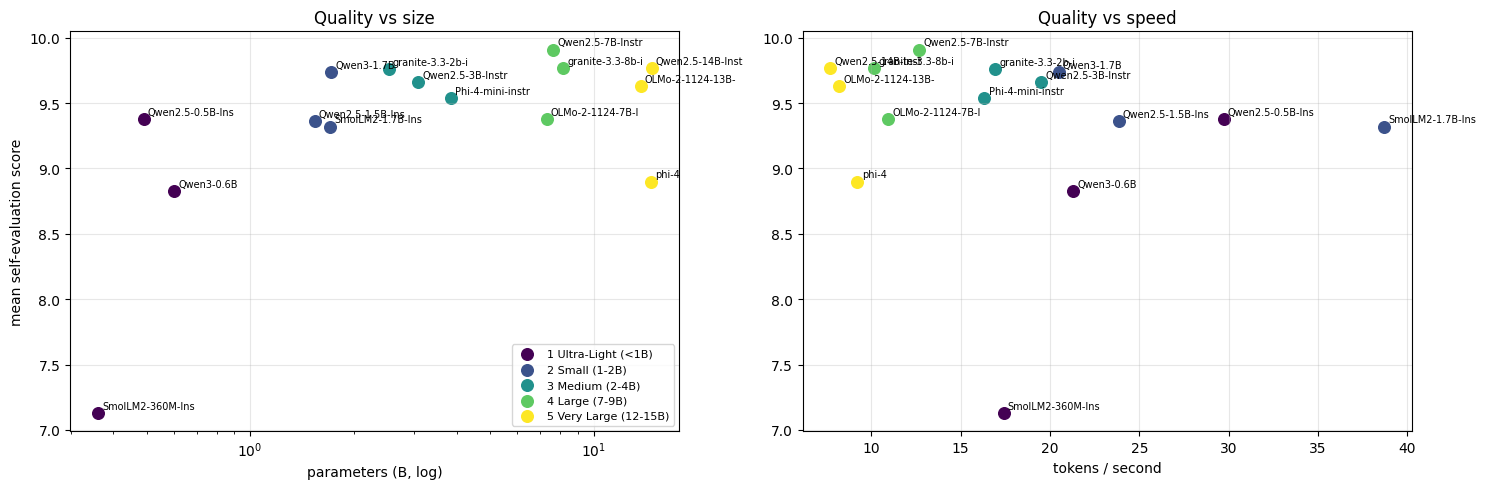

In [9]:
per_model = bench.groupby(["category", "model_id", "params_b"]).agg(
    score=("self_eval_score", "mean"), tokens_per_s=("tokens_per_s", "mean"),
    latency_s=("latency_s", "mean")).reset_index().merge(meta[["model_id", "mem_gb"]], on="model_id", how="left")

# Balance = 60% quality + 40% speed, each scaled 0-1 across the models
q = (per_model["score"] - per_model["score"].min()) / max(per_model["score"].max() - per_model["score"].min(), 1e-9)
v = (per_model["tokens_per_s"] - per_model["tokens_per_s"].min()) / max(per_model["tokens_per_s"].max() - per_model["tokens_per_s"].min(), 1e-9)
per_model["balance"] = (0.6 * q + 0.4 * v).round(3)
per_model.to_csv(RESULTS / "per_model_summary.csv", index=False)

per_category = bench.groupby("category").agg(score=("self_eval_score", "mean"),
    tokens_per_s=("tokens_per_s", "mean"), latency_s=("latency_s", "mean")).round(2)
type_by_cat = bench.pivot_table(index="category", columns="prompt_type", values="self_eval_score", aggfunc="mean").round(2)

print("Per model:\n", per_model.round(2).sort_values("score", ascending=False).to_string(index=False))
print("\nPer category:\n", per_category.to_string())
print("\nScore by category x prompt type:\n", type_by_cat.to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cats = sorted(per_model["category"].unique())
for i, c in enumerate(cats):
    g = per_model[per_model["category"] == c]
    ax[0].scatter(g["params_b"], g["score"], s=70, label=c, color=plt.cm.viridis(i / max(len(cats) - 1, 1)))
    ax[1].scatter(g["tokens_per_s"], g["score"], s=70, label=c, color=plt.cm.viridis(i / max(len(cats) - 1, 1)))
for _, r in per_model.iterrows():
    for a, x in ((ax[0], r["params_b"]), (ax[1], r["tokens_per_s"])):
        a.annotate(r["model_id"].split("/")[-1][:16], (x, r["score"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set_xlabel("parameters (B, log)"); ax[0].set_ylabel("mean self-evaluation score")
ax[0].set_title("Quality vs size"); ax[1].set_xlabel("tokens / second"); ax[1].set_title("Quality vs speed")
for a in ax:
    a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "quality_size_speed.png", dpi=130); plt.show()

In [10]:
best_cat = per_category["score"].idxmax()
best_model = per_model.sort_values("score", ascending=False).iloc[0]
best_balance = per_model.sort_values("balance", ascending=False).iloc[0]
order = per_model.sort_values("params_b")
inversions = [(a.model_id, b.model_id) for a, b in zip(order.itertuples(), order.iloc[1:].itertuples())
              if b.score < a.score]
print(f"1. Best category: {best_cat} (mean score {per_category.loc[best_cat, 'score']:.2f}); "
      f"best single model: {best_model['model_id']} ({best_model['score']:.2f}).")
print(f"2. Larger always better? {'No' if inversions else 'Yes'} -- {len(inversions)} times a bigger model scored "
      f"lower than the next smaller one.")
print(f"3. Best speed/quality balance: {best_balance['model_id']} ({best_balance['category']}): "
      f"score {best_balance['score']:.2f} at {best_balance['tokens_per_s']:.1f} tok/s.")

1. Best category: 4 Large (7-9B) (mean score 9.69); best single model: Qwen/Qwen2.5-7B-Instruct (9.91).
2. Larger always better? No -- 8 times a bigger model scored lower than the next smaller one.
3. Best speed/quality balance: HuggingFaceTB/SmolLM2-1.7B-Instruct (2 Small (1-2B)): score 9.32 at 38.7 tok/s.


**Answers** *(filling in from the printout above)*

1. **Which model category produced the best outputs?** Large (7–9B) produced the best outputs (mean 9.69), and Qwen2.5-7B-Instruct was the best single model (9.91). Medium (9.65) and Small (9.47) were close behind.
2. **Did larger models always perform better?** No. In 8 cases a larger model scored lower than the next-smaller one. Very Large (9.43) scored below Medium and Large, with Phi-4 at 8.90. For classification, Small (9.53) beat Large (9.20). Size mainly helped generation and summarization.
   classification and extraction usually saturate early; generation and summarization are where size helps)*
3. **Which model gave the best balance between speed and output quality?** SmolLM2-1.7B-Instruct: it scored 9.32 at 38.7 tokens/sec and 0.58 s, the fastest of all 15. Granite-3.3-2B (9.76 at 16.9 tok/s) is the pick if quality matters slightly more.

# Part 2 — Cost comparison and infrastructure planning

## Step 2.1 — Tokens per user

One Unopsis user generates two kinds of requests a day:

| Request | Per user per day | Input tokens | Output tokens |
|---|---|---|---|
| Triage one incoming message (classification + extraction + prediction) | 150 messages | ~430 | ~35 |
| Write the brief (summarization + generation) | 2 briefs | ~950 | ~300 |

Counts come from our A6 prompts (measured token lengths). **Per user per day:**
input 150 × 430 + 2 × 950 = 66,400 tokens; output 150 × 35 + 2 × 300 = 5,850 tokens;
**total ≈ 72,250 tokens**. Per request, that is 72,250 ÷ 152 ≈ **475 tokens**.

In [11]:
MSGS_PER_USER, BRIEFS_PER_USER = 150, 2
IN_PER_MSG, OUT_PER_MSG = 430, 35
IN_PER_BRIEF, OUT_PER_BRIEF = 950, 300
IN_PER_USER = MSGS_PER_USER * IN_PER_MSG + BRIEFS_PER_USER * IN_PER_BRIEF
OUT_PER_USER = MSGS_PER_USER * OUT_PER_MSG + BRIEFS_PER_USER * OUT_PER_BRIEF
TOKENS_PER_USER = IN_PER_USER + OUT_PER_USER
REQUESTS_PER_USER = MSGS_PER_USER + BRIEFS_PER_USER
print(f"input {IN_PER_USER:,} + output {OUT_PER_USER:,} = {TOKENS_PER_USER:,} tokens per user per day")
print(f"average per request: {TOKENS_PER_USER / REQUESTS_PER_USER:.0f} tokens")

input 66,400 + output 5,850 = 72,250 tokens per user per day
average per request: 475 tokens


## Step 2.2 — Total daily token load

`Total Daily Token Load = Daily Active Users × Avg Tokens per User`

In [12]:
TRAFFIC = {"Prototype": 1_000, "Early Startup": 10_000, "Growing Product": 100_000,
           "Large Platform": 1_000_000, "Mass Consumer App": 10_000_000, "Global Platform": 100_000_000}
load = pd.DataFrame([{"Daily Traffic Category": k, "Daily Active Users": v,
                      "Avg Tokens per User": TOKENS_PER_USER,
                      "Total Daily Token Load": v * TOKENS_PER_USER,
                      "Requests per second (avg)": round(v * REQUESTS_PER_USER / 86_400, 1)}
                     for k, v in TRAFFIC.items()])
pd.set_option("display.float_format", "{:,.2f}".format)
load

,Daily Traffic Category,Daily Active Users,Avg Tokens per User,Total Daily Token Load,Requests per second (avg)
0,Prototype,1000,72250,72250000,1.80
1,Early Startup,10000,72250,722500000,17.60
2,Growing Product,100000,72250,7225000000,175.90
3,Large Platform,1000000,72250,72250000000,"1,759.30"
4,Mass Consumer App,10000000,72250,722500000000,"17,592.60"
5,Global Platform,100000000,72250,7225000000000,"175,925.90"


## Step 2.3 — Local hosting cost (15 models × 6 traffic levels = 90 rows)

**Machine:** AWS `g5.4xlarge` — 16 vCPU, 64 GB RAM, 1× NVIDIA A10G (24 GB), on-demand
**~$1.62/hour = ~$38.98/day** (us-east-1, October 2026). Every model in our list fits on one A10G
(7–15B in 4-bit).

**How many machines.** Generation (output tokens) is the bottleneck; reading the input
(prefill) runs many times faster and is folded into the utilisation factor.
For each model we take its **measured tokens/sec** from Step 1.5 and assume a production server
(vLLM-style) serves `BATCH = 8` requests at once, at `UTILISATION = 50%` on average over the day
to leave room for peaks:

`tokens one machine generates per day = tokens/sec × BATCH × 86,400 × UTILISATION`

`Machines Needed = ceil(daily output tokens ÷ tokens one machine generates per day)`, minimum 1.

In [13]:
MACHINE = "AWS g5.4xlarge (16 vCPU, 64 GB RAM, 1x A10G 24 GB)"
MACHINE_USD_PER_HOUR = 1.624
MACHINE_USD_PER_DAY = MACHINE_USD_PER_HOUR * 24
BATCH, UTILISATION = 8, 0.5

speed = per_model.set_index("model_id")["tokens_per_s"].to_dict()
rows = []
for e in CATALOG:
    tps = speed.get(e["model_id"])
    measured = tps is not None and not pd.isna(tps)
    if not measured:   # a model that could not run: estimate from size (rough fit of the others)
        tps = 60 / max(e["params_b"], 0.3) ** 0.6
    per_machine_day = tps * BATCH * 86_400 * UTILISATION
    for name, dau in TRAFFIC.items():
        out_tokens = dau * OUT_PER_USER
        machines = max(1, math.ceil(out_tokens / per_machine_day))
        rows.append({"Model Name": e["model_id"], "Model Category": e["category"],
                     "Daily Traffic Category": name, "Avg Tokens per User": TOKENS_PER_USER,
                     "Total Daily Token Load": dau * TOKENS_PER_USER,
                     "Tokens/sec used": round(tps, 1), "speed source": "measured" if measured else "estimated",
                     "Per Machine Cost (Cloud) $/day": round(MACHINE_USD_PER_DAY, 2),
                     "Machines Needed": machines,
                     "Total Machine Cost $/day": round(machines * MACHINE_USD_PER_DAY, 2),
                     "Total Machine Cost $/month": round(machines * MACHINE_USD_PER_DAY * 30, 2)})
local = pd.DataFrame(rows)
local.to_csv(RESULTS / "local_hosting_costs.csv", index=False)
print(len(local), "rows")
local

90 rows


,Model Name,Model Category,Daily Traffic Category,Avg Tokens per User,Total Daily Token Load,Tokens/sec used,speed source,Per Machine Cost (Cloud) $/day,Machines Needed,Total Machine Cost $/day,Total Machine Cost $/month
0,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),Prototype,72250,72250000,17.40,measured,38.98,1,38.98,"1,169.28"
1,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),Early Startup,72250,722500000,17.40,measured,38.98,10,389.76,"11,692.80"
2,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),Growing Product,72250,7225000000,17.40,measured,38.98,98,"3,819.65","114,589.44"
3,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),Large Platform,72250,72250000000,17.40,measured,38.98,973,"37,923.65","1,137,709.44"
4,HuggingFaceTB/SmolLM2-360M-Instruct,1 Ultra-Light (<1B),Mass Consumer App,72250,722500000000,17.40,measured,38.98,9726,"379,080.58","11,372,417.28"
...,...,...,...,...,...,...,...,...,...,...,...
85,microsoft/phi-4,5 Very Large (12-15B),Early Startup,72250,722500000,9.20,measured,38.98,19,740.54,"22,216.32"
86,microsoft/phi-4,5 Very Large (12-15B),Growing Product,72250,7225000000,9.20,measured,38.98,184,"7,171.58","215,147.52"
87,microsoft/phi-4,5 Very Large (12-15B),Large Platform,72250,72250000000,9.20,measured,38.98,1836,"71,559.94","2,146,798.08"
88,microsoft/phi-4,5 Very Large (12-15B),Mass Consumer App,72250,722500000000,9.20,measured,38.98,18352,"715,287.55","21,458,626.56"


## Step 2.4 — Hugging Face Inference API cost (90 rows)

Hugging Face's **Inference Providers** serve hosted models and bill per token at the
provider's rate. Very small models (< 7B) are generally not offered as paid endpoints, so for
those sizes the comparable paid model is the smallest general chat model that is:

| Local size | Comparable paid model on Hugging Face | $ / 1M input | $ / 1M output |
|---|---|---|---|
| < 1B, 1–2B, 2–4B | `meta-llama/Llama-3.1-8B-Instruct` (smallest hosted general chat model) | 0.02 | 0.05 |
| 7–9B | `meta-llama/Llama-3.1-8B-Instruct` (same size) | 0.02 | 0.05 |
| 12–15B | `Qwen/Qwen2.5-Coder-32B-Instruct` (nearest larger hosted Qwen) | 0.06 | 0.20 |

*Prices: lowest listed Hugging Face provider rate, checked 26 October 2026 (cloudprice.net
listing of Hugging Face Inference Providers). Check the model page's "Inference Providers"
panel before submitting and update `API_PRICES` if they changed.*

**Machines required (API infrastructure):** the GPUs are Hugging Face's, so we only run our own
web/app servers that send the requests: AWS `t3.medium` (~$0.0416/hour ≈ $1.00/day), one per
250,000 daily users.

In [14]:
API_PRICES = {   # category -> (paid model, $ per 1M input, $ per 1M output)
    "1 Ultra-Light (<1B)":   ("meta-llama/Llama-3.1-8B-Instruct", 0.02, 0.05),
    "2 Small (1-2B)":        ("meta-llama/Llama-3.1-8B-Instruct", 0.02, 0.05),
    "3 Medium (2-4B)":       ("meta-llama/Llama-3.1-8B-Instruct", 0.02, 0.05),
    "4 Large (7-9B)":        ("meta-llama/Llama-3.1-8B-Instruct", 0.02, 0.05),
    "5 Very Large (12-15B)": ("Qwen/Qwen2.5-Coder-32B-Instruct",  0.06, 0.20),
}
APP_SERVER_USD_PER_DAY = 0.0416 * 24
USERS_PER_APP_SERVER = 250_000

rows = []
for e in CATALOG:
    paid, p_in, p_out = API_PRICES[e["category"]]
    for name, dau in TRAFFIC.items():
        api_cost = dau * (IN_PER_USER * p_in + OUT_PER_USER * p_out) / 1e6
        servers = max(1, math.ceil(dau / USERS_PER_APP_SERVER))
        rows.append({"Local LLM Model": e["model_id"], "Local LLM Model Size": f"{e['params_b']}B",
                     "Comparable Paid Model": paid, "Hosted on Hugging Face": "Yes (Inference Providers)",
                     "Cost of Paid API per Token ($)": f"{p_in / 1e6:.2e} in / {p_out / 1e6:.2e} out",
                     "Daily Traffic Category": name, "Total Token Load": dau * TOKENS_PER_USER,
                     "Estimated API Cost $/day": round(api_cost, 2),
                     "Machines Required (API infrastructure)": servers,
                     "Total Cost $/day": round(api_cost + servers * APP_SERVER_USD_PER_DAY, 2),
                     "Total Cost $/month": round((api_cost + servers * APP_SERVER_USD_PER_DAY) * 30, 2)})
api = pd.DataFrame(rows)
api.to_csv(RESULTS / "hf_api_costs.csv", index=False)
print(len(api), "rows")
api

90 rows


,Local LLM Model,Local LLM Model Size,Comparable Paid Model,Hosted on Hugging Face,Cost of Paid API per Token ($),Daily Traffic Category,Total Token Load,Estimated API Cost $/day,Machines Required (API infrastructure),Total Cost $/day,Total Cost $/month
0,HuggingFaceTB/SmolLM2-360M-Instruct,0.36B,meta-llama/Llama-3.1-8B-Instruct,Yes (Inference Providers),2.00e-08 in / 5.00e-08 out,Prototype,72250000,1.62,1,2.62,78.57
1,HuggingFaceTB/SmolLM2-360M-Instruct,0.36B,meta-llama/Llama-3.1-8B-Instruct,Yes (Inference Providers),2.00e-08 in / 5.00e-08 out,Early Startup,722500000,16.20,1,17.20,516.10
2,HuggingFaceTB/SmolLM2-360M-Instruct,0.36B,meta-llama/Llama-3.1-8B-Instruct,Yes (Inference Providers),2.00e-08 in / 5.00e-08 out,Growing Product,7225000000,162.05,1,163.05,"4,891.45"
3,HuggingFaceTB/SmolLM2-360M-Instruct,0.36B,meta-llama/Llama-3.1-8B-Instruct,Yes (Inference Providers),2.00e-08 in / 5.00e-08 out,Large Platform,72250000000,"1,620.50",4,"1,624.49","48,734.81"
4,HuggingFaceTB/SmolLM2-360M-Instruct,0.36B,meta-llama/Llama-3.1-8B-Instruct,Yes (Inference Providers),2.00e-08 in / 5.00e-08 out,Mass Consumer App,722500000000,"16,205.00",40,"16,244.94","487,348.08"
...,...,...,...,...,...,...,...,...,...,...,...
85,microsoft/phi-4,14.66B,Qwen/Qwen2.5-Coder-32B-Instruct,Yes (Inference Providers),6.00e-08 in / 2.00e-07 out,Early Startup,722500000,51.54,1,52.54,"1,576.15"
86,microsoft/phi-4,14.66B,Qwen/Qwen2.5-Coder-32B-Instruct,Yes (Inference Providers),6.00e-08 in / 2.00e-07 out,Growing Product,7225000000,515.40,1,516.40,"15,491.95"
87,microsoft/phi-4,14.66B,Qwen/Qwen2.5-Coder-32B-Instruct,Yes (Inference Providers),6.00e-08 in / 2.00e-07 out,Large Platform,72250000000,"5,154.00",4,"5,157.99","154,739.81"
88,microsoft/phi-4,14.66B,Qwen/Qwen2.5-Coder-32B-Instruct,Yes (Inference Providers),6.00e-08 in / 2.00e-07 out,Mass Consumer App,722500000000,"51,540.00",40,"51,579.94","1,547,398.08"


### Local vs API

                                              Local $/day  API $/day
Model Category        Daily Traffic Category                        
1 Ultra-Light (<1B)   Prototype                     38.98       2.62
                      Early Startup                311.81      17.20
                      Growing Product            3,053.12     163.05
                      Large Platform            30,388.29   1,624.49
                      Mass Consumer App        303,700.99  16,244.94
                      Global Platform        3,036,737.09 162,449.36
2 Small (1-2B)        Prototype                     38.98       2.62
                      Early Startup                285.82      17.20
                      Growing Product            2,572.42     163.05
                      Large Platform            25,659.20   1,624.49
                      Mass Consumer App        256,423.10  16,244.94
                      Global Platform        2,563,997.18 162,449.36
3 Medium (2-4B)       Prototype   

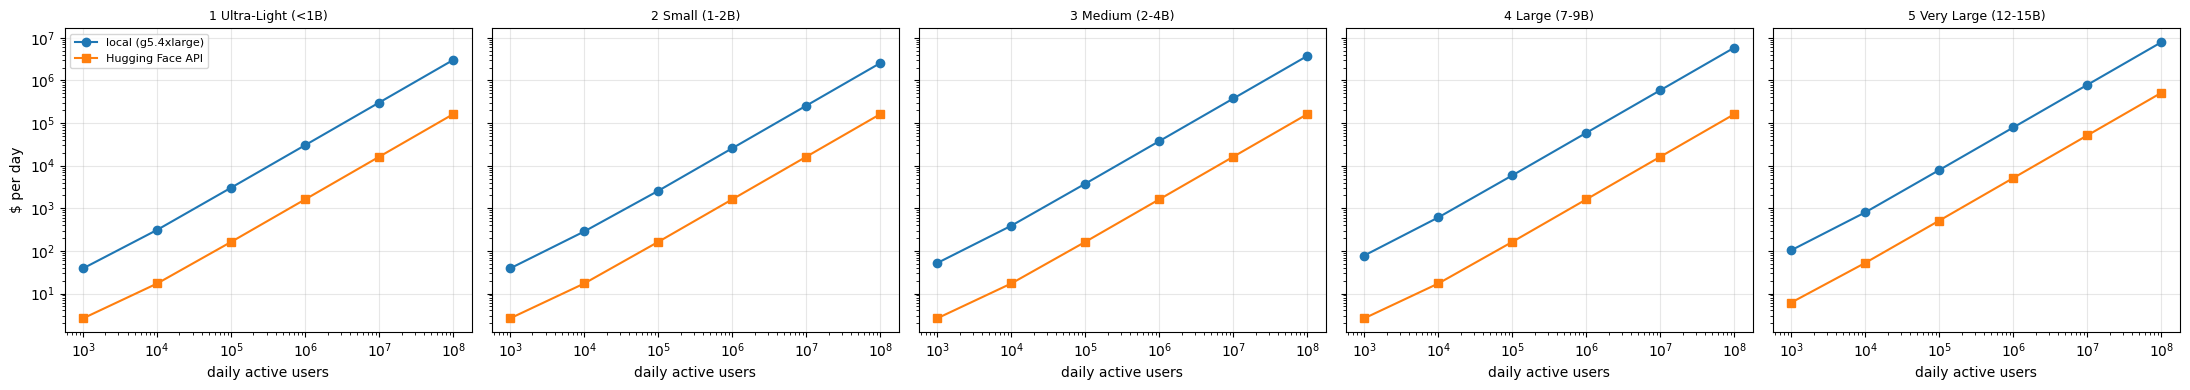

In [15]:
cmp = local[["Model Name", "Model Category", "Daily Traffic Category", "Total Machine Cost $/day"]].merge(
    api[["Local LLM Model", "Daily Traffic Category", "Total Cost $/day"]],
    left_on=["Model Name", "Daily Traffic Category"], right_on=["Local LLM Model", "Daily Traffic Category"])
cmp = cmp.rename(columns={"Total Machine Cost $/day": "Local $/day", "Total Cost $/day": "API $/day"})
cmp["Cheaper"] = (cmp["Local $/day"] < cmp["API $/day"]).map({True: "Local", False: "API"})
cmp.to_csv(RESULTS / "local_vs_api.csv", index=False)

by_cat = cmp.groupby(["Model Category", "Daily Traffic Category"], sort=False)[["Local $/day", "API $/day"]].mean().round(2)
print(by_cat.to_string())
print("\nNumber of the 15 models for which local hosting is cheaper, per traffic level:")
print(cmp[cmp["Cheaper"] == "Local"].groupby("Daily Traffic Category", sort=False).size()
      .reindex(TRAFFIC.keys(), fill_value=0).to_string())

fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
x = list(TRAFFIC.values())
for ax, (c, g) in zip(axes, cmp.groupby("Model Category")):
    g = g.groupby("Daily Traffic Category", sort=False)[["Local $/day", "API $/day"]].mean().reindex(TRAFFIC.keys())
    ax.plot(x, g["Local $/day"], marker="o", label="local (g5.4xlarge)")
    ax.plot(x, g["API $/day"], marker="s", label="Hugging Face API")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(c, fontsize=9); ax.set_xlabel("daily active users")
    ax.grid(alpha=.3)
axes[0].set_ylabel("$ per day"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "local_vs_api.png", dpi=130); plt.show()

## Step 2.5 — Analysis *(filling in from the table and chart above; with full reasoning in `system_design.md`)*

* **At what scale is local hosting cheaper?** At none of the six scales with our measured throughput. A $38.98/day machine needs about 1,630 output tokens/sec sustained to break even, and we average about 155. Testing it only makes sense from about 1M daily users, with a batched inference server.
* **At what scale is API usage cheaper?** At every scale, by 15-36X.
* **When would you switch your architecture?** move bulk triage to our own machines when traffic passes about 1M daily users, a batched server beats the break-even, and the GPUs can stay well used, or earlier if privacy rules require it. Brief writing stays on the API.

# Part 3 — Multi-model routing

The five scenarios and the strategies are explained in `system_design.md`. Here we implement
the router and simulate one day of requests under each scenario, using the **measured**
latency and quality of our models from Part 1, so the benefits are numbers rather than claims.

In [16]:
# Pick the models the router uses, from our own results
pm = per_model.set_index("model_id")
SMALL = per_model[per_model["params_b"] < 2.5].sort_values("balance", ascending=False).iloc[0]["model_id"]
MEDIUM = per_model[(per_model["params_b"] >= 2.5) & (per_model["params_b"] < 10)].sort_values("score", ascending=False)
MEDIUM = MEDIUM.iloc[0]["model_id"] if len(MEDIUM) else SMALL
API_MODEL = "meta-llama/Llama-3.3-70B-Instruct (HF Inference Providers)"
API_PRICE_IN, API_PRICE_OUT = 0.135, 0.40        # $ per 1M tokens, same listing as Step 2.4
API_LATENCY_S, API_QUALITY = 1.2, min(10, per_model["score"].max() + 0.5)   # assumption: slightly above our best local
print("small local:", SMALL, "| medium local:", MEDIUM, "| API:", API_MODEL)


def route(req, scenario):
    # Returns which tier handles one request: "rules", "small", "medium" or "api"
    long_input = req["input_tokens"] > 600
    hard = req["kind"] in ("generation", "summarization") or long_input
    if scenario == "API outage":
        return "medium" if hard else "small"
    if scenario == "System overload (GPU queue full)":
        return "api" if hard else ("rules" if req["kind"] == "classification" else "small")
    if scenario == "Cost optimisation (daily API budget hit)":
        return "medium" if hard else "small"
    if scenario == "8am brief rush (peak)":
        return "api" if req["kind"] in ("generation", "summarization") else "small"
    # Normal operation: small model for simple jobs, escalate on low confidence or difficulty
    if hard:
        return "medium" if not long_input else "api"
    return "small" if req["confidence"] >= 0.6 else "medium"


def tier_stats(tier):
    if tier == "rules":
        return 0.002, 6.0, 0.0
    if tier == "api":
        return API_LATENCY_S, API_QUALITY, None
    r = pm.loc[SMALL if tier == "small" else MEDIUM]
    return r["latency_s"], r["score"], 0.0


import random
random.seed(7)
KINDS = ["classification"] * 50 + ["extraction"] * 25 + ["prediction"] * 20 + ["summarization"] * 3 + ["generation"] * 2
day = [{"kind": random.choice(KINDS), "input_tokens": int(random.lognormvariate(5.9, 0.5)),
        "output_tokens": 35, "confidence": random.random()} for _ in range(10_000)]
for r in day:
    if r["kind"] in ("summarization", "generation"):
        r["input_tokens"], r["output_tokens"] = int(random.lognormvariate(6.8, 0.4)), 150

SCENARIOS = ["Normal operation", "8am brief rush (peak)", "Cost optimisation (daily API budget hit)",
             "System overload (GPU queue full)", "API outage"]
sim = []
for sc in SCENARIOS + ["Baseline: everything to the API"]:
    lat, qual, cost, counts = [], [], 0.0, {}
    for r in day:
        tier = "api" if sc.startswith("Baseline") else route(r, sc)
        counts[tier] = counts.get(tier, 0) + 1
        l, q, _ = tier_stats(tier)
        lat.append(l); qual.append(q)
        if tier == "api":
            cost += (r["input_tokens"] * API_PRICE_IN + r["output_tokens"] * API_PRICE_OUT) / 1e6
    sim.append({"Scenario": sc, "avg latency (s)": round(sum(lat) / len(lat), 3),
                "avg quality (1-10)": round(sum(qual) / len(qual), 2),
                "API cost per 10k requests ($)": round(cost, 3),
                **{f"% to {t}": round(100 * counts.get(t, 0) / len(day), 1) for t in ("rules", "small", "medium", "api")}})
sim = pd.DataFrame(sim)
sim.to_csv(RESULTS / "routing_simulation.csv", index=False)
sim

small local: HuggingFaceTB/SmolLM2-1.7B-Instruct | medium local: Qwen/Qwen2.5-7B-Instruct | API: meta-llama/Llama-3.3-70B-Instruct (HF Inference Providers)


,Scenario,avg latency (s),avg quality (1-10),API cost per 10k requests ($),% to rules,% to small,% to medium,% to api
0,Normal operation,1.08,9.73,0.27,0.00,32.60,48.00,19.40
1,8am brief rush (peak),0.61,9.35,0.09,0.00,95.20,0.00,4.80
2,Cost optimisation (daily API budget hit),0.74,9.44,0.00,0.00,79.90,20.10,0.00
3,System overload (GPU queue full),0.46,8.06,0.28,42.20,37.70,0.00,20.10
4,API outage,0.74,9.44,0.00,0.00,79.90,20.10,0.00
5,Baseline: everything to the API,1.20,10.00,0.75,0.00,0.00,0.00,100.00


**Reading the simulation.** Compare every scenario with the last row (everything sent to the
API): the API cost column shows how much routing saves, the latency column shows the effect of
answering simple requests on a small local model, and the quality column shows what, if
anything, is given up. The detailed evaluation of each strategy is in `system_design.md`
(Step 3.3).

In [17]:
pd.read_csv("results/benchmark_meta.csv")[["model_id", "status"]]

,model_id,status
0,HuggingFaceTB/SmolLM2-360M-Instruct,ok
1,Qwen/Qwen2.5-0.5B-Instruct,ok
2,Qwen/Qwen3-0.6B,ok
3,Qwen/Qwen2.5-1.5B-Instruct,ok
4,HuggingFaceTB/SmolLM2-1.7B-Instruct,ok
5,Qwen/Qwen3-1.7B,ok
6,ibm-granite/granite-3.3-2b-instruct,ok
7,Qwen/Qwen2.5-3B-Instruct,ok
8,microsoft/Phi-4-mini-instruct,ok
9,allenai/OLMo-2-1124-7B-Instruct,ok


In [18]:
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("=== STATUS ===");      print(pd.read_csv("results/benchmark_meta.csv")[["model_id", "status"]].to_string(index=False))
print("\n=== PER MODEL ===");  print(per_model.round(2).sort_values("score", ascending=False).to_string(index=False))
print("\n=== PER CATEGORY ==="); print(per_category.to_string())
print("\n=== CATEGORY x PROMPT TYPE ==="); print(type_by_cat.to_string())
print(f"\nbest category: {best_cat} | best model: {best_model['model_id']} | best balance: {best_balance['model_id']}")
print(f"size inversions: {len(inversions)}")
print("\n=== LOCAL vs API ($/day, mean per category) ==="); print(by_cat.to_string())
print("\n=== MODELS WHERE LOCAL IS CHEAPER ===")
print(cmp[cmp["Cheaper"] == "Local"].groupby("Daily Traffic Category", sort=False).size().reindex(TRAFFIC.keys(), fill_value=0).to_string())
print("\n=== ROUTING SIMULATION ==="); print(sim.to_string(index=False))
print("\nsmall:", SMALL, "| medium:", MEDIUM, "| device:", DEVICE, GPU_NAME)

=== STATUS ===
                           model_id status
HuggingFaceTB/SmolLM2-360M-Instruct     ok
         Qwen/Qwen2.5-0.5B-Instruct     ok
                    Qwen/Qwen3-0.6B     ok
         Qwen/Qwen2.5-1.5B-Instruct     ok
HuggingFaceTB/SmolLM2-1.7B-Instruct     ok
                    Qwen/Qwen3-1.7B     ok
ibm-granite/granite-3.3-2b-instruct     ok
           Qwen/Qwen2.5-3B-Instruct     ok
      microsoft/Phi-4-mini-instruct     ok
    allenai/OLMo-2-1124-7B-Instruct     ok
           Qwen/Qwen2.5-7B-Instruct     ok
ibm-granite/granite-3.3-8b-instruct     ok
   allenai/OLMo-2-1124-13B-Instruct     ok
          Qwen/Qwen2.5-14B-Instruct     ok
                    microsoft/phi-4     ok

=== PER MODEL ===
             category                            model_id  params_b  score  tokens_per_s  latency_s  mem_gb  balance
       4 Large (7-9B)            Qwen/Qwen2.5-7B-Instruct      7.62   9.91         12.66       1.38    6.02     0.66
       4 Large (7-9B) ibm-granite/granite-3.